# 🌳 MODEL XGBoost (FINAL) — Prediksi Volatilitas Return Saham
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Ilda Nurida — 6032251068 | Pembimbing: Dr. Ir. Ahmad Saikhu, S.Si, MT.**

### 🔧 Versi final — konsisten dgn LSTM
- **Set fitur identik (28)** dgn notebook LSTM final → perbandingan RM-3 sah.
- Evaluasi pada **skala volatilitas asli** (inverse-transform MinMax) → sebanding lintas model.
- **TimeSeriesSplit** utk tuning (cegah data leakage). Reprodusibel (seed tetap).
- Output → `xgboost_{emiten}.pkl`, `tabel_evaluasi_xgboost.csv`, `tabel_hyperparameter_xgboost.csv`,
  `hasil_prediksi_xgboost.csv`, gambar feature importance & aktual-vs-prediksi.

## ⚙️ CELL 1 — Import, Konfigurasi, Feature Set

In [48]:
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor
import xgboost as xgb

warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({
    'font.size': 11,
    'figure.dpi': 150
})

# ============================================================
# ROOT AUTO-DETECT
# ============================================================
ROOT = Path(os.getcwd())

for _ in range(6):
    if (ROOT / '03_dataset').exists():
        break
    ROOT = ROOT.parent

if not (ROOT / '03_dataset').exists():
    ROOT = Path(
        r'e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
        r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026'
    )

# ============================================================
# DIRECTORY
# ============================================================
DIR_FINAL  = ROOT / '03_dataset' / 'final'
DIR_MODEL  = ROOT / '04_model' / 'xgboost'
DIR_TABEL  = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'

for d in [DIR_MODEL, DIR_TABEL, DIR_GAMBAR]:
    d.mkdir(parents=True, exist_ok=True)

# ============================================================
# CONFIG
# ============================================================
URUTAN_EMITEN = ['ADRO','ADMR','ITMG','PTBA','MEDC','AKRA','PGAS']

# Target forecast T+1
KOLOM_Y = 'Target_Volatility'

LAKUKAN_TUNING = True
N_ITER_TUNING = 25

# ============================================================
# FEATURE LIST (sinkron dengan CSV final)
# ============================================================
KOLOM_X_KANDIDAT = [
    # Technical
    'Log_Return',
    'MA5', 'MA10', 'MA20',
    'EMA12', 'EMA26',
    'RSI14',
    'MACD', 'MACD_Signal', 'MACD_Hist',
    'BB_Upper', 'BB_Lower', 'BB_Width', 'BB_PctB',
    'Stoch_K', 'Stoch_D',
    'Volume', 'Volume_Change', 'Volume_MA5',

    # Sentiment
    'Skor_Sentimen',
    'N_Berita',
    'Ada_Berita',
    'Skor_Sentimen_Lag1',
    'Sentiment_MA20',
    'Sentiment_STD20',
    'Sentiment_Min20',
    'Sentiment_Max20'
]

# ============================================================
# BASELINE MODEL
# ============================================================
XGB_BASELINE = dict(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=SEED
)

print('=' * 70)
print('✅ XGBOOST CONFIG READY (FINAL)')
print('=' * 70)
print(f'ROOT         : {ROOT}')
print(f'Target Y     : {KOLOM_Y}')
print(f'Jumlah fitur : {len(KOLOM_X_KANDIDAT)}')
print(f'XGBoost ver  : {xgb.__version__}')
print('=' * 70)

✅ XGBOOST CONFIG READY (FINAL)
ROOT         : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
Target Y     : Target_Volatility
Jumlah fitur : 27
XGBoost ver  : 3.2.0


In [49]:
print(KOLOM_Y)
print({e: len(dict_kolom_x[e]) for e in dict_kolom_x})

Target_Volatility
{'ADRO': 27, 'ADMR': 27, 'ITMG': 27, 'PTBA': 27, 'MEDC': 27, 'AKRA': 27, 'PGAS': 27}


## 🔧 CELL 2 — Fungsi Bantu

In [50]:
# ── Fungsi bantu: inverse-transform & metrik (skala volatilitas ASLI) ──
def inverse_transform(nilai, scaler_df, kolom=KOLOM_Y):
    """Kembalikan nilai ter-MinMax-scale ke skala asli. Konsisten utk XGBoost & LSTM."""
    if scaler_df is None or kolom not in scaler_df.index:
        return np.asarray(nilai, dtype=float)
    cmin = float(scaler_df.loc[kolom, 'min']); cmax = float(scaler_df.loc[kolom, 'max'])
    return np.asarray(nilai, dtype=float) * (cmax - cmin) + cmin

def _mape(y, p, eps=1e-8):
    y=np.asarray(y,float); p=np.asarray(p,float); m=np.abs(y)>eps
    return np.nan if m.sum()==0 else float(np.mean(np.abs((y[m]-p[m])/y[m]))*100)

def _smape(y, p, eps=1e-8):
    y=np.asarray(y,float); p=np.asarray(p,float); d=np.abs(y)+np.abs(p); m=d>eps
    return np.nan if m.sum()==0 else float(np.mean(2*np.abs(p[m]-y[m])/d[m])*100)

def _qlike(y, p, eps=1e-12):
    ht=np.maximum(np.asarray(y,float)**2,eps); hp=np.maximum(np.asarray(p,float)**2,eps)
    return float(np.mean(np.log(hp)+ht/hp))

def evaluasi_semua_metrik(y_true, y_pred):
    return {
        'RMSE' : float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE'  : float(mean_absolute_error(y_true, y_pred)),
        'MAPE (%)' : round(_mape(y_true, y_pred), 2),
        'sMAPE (%)': round(_smape(y_true, y_pred), 2),
        'R2'   : round(float(r2_score(y_true, y_pred)), 4),
        'QLIKE': round(_qlike(y_true, y_pred), 4),
    }

def interpretasi_mape(m):
    if   m < 10: return 'Sangat Baik'
    elif m < 20: return 'Baik'
    elif m < 50: return 'Cukup'
    else       : return 'Kurang Baik'

print('✅ Fungsi bantu siap (evaluasi pada skala volatilitas asli).')

✅ Fungsi bantu siap (evaluasi pada skala volatilitas asli).


## 📂 CELL 3 — Load Dataset per Emiten (allowlist 28 fitur)

In [51]:
dict_train, dict_test, dict_scaler, dict_kolom_x = {}, {}, {}, {}

for emiten in URUTAN_EMITEN:
    p_tr = DIR_FINAL / f'dataset_train_{emiten}.csv'
    p_te = DIR_FINAL / f'dataset_test_{emiten}.csv'
    p_sc = DIR_FINAL / f'scaler_params_{emiten}.csv'
    if not p_tr.exists() or not p_te.exists():
        print(f'  ⚠️  {emiten}: file train/test tidak ditemukan, skip'); continue

    df_tr = pd.read_csv(p_tr, encoding='utf-8-sig')
    df_te = pd.read_csv(p_te, encoding='utf-8-sig')
    for d in (df_tr, df_te):
        if 'Date' in d.columns:
            d['Date'] = pd.to_datetime(d['Date'], errors='coerce')

    # ── ALLOWLIST: pilih fitur dari KOLOM_X_KANDIDAT yg ADA di train DAN test ──
    kolom_x = [c for c in KOLOM_X_KANDIDAT if c in df_tr.columns and c in df_te.columns]
    hilang  = [c for c in KOLOM_X_KANDIDAT if c not in kolom_x]

    df_tr = df_tr.dropna(subset=kolom_x + [KOLOM_Y]).reset_index(drop=True)
    df_te = df_te.dropna(subset=kolom_x + [KOLOM_Y]).reset_index(drop=True)
    scaler = pd.read_csv(p_sc, index_col=0, encoding='utf-8-sig') if p_sc.exists() else None

    dict_train[emiten]=df_tr; dict_test[emiten]=df_te
    dict_scaler[emiten]=scaler; dict_kolom_x[emiten]=kolom_x

    ket_h = f' | ⚠️ fitur hilang: {hilang}' if hilang else ''
    print(f'  ✅ {emiten}: train={len(df_tr):,} | test={len(df_te):,} | '
          f'fitur={len(kolom_x)} | sentimen={"Skor_Sentimen" in kolom_x}{ket_h}')

n_fitur_set = {len(v) for v in dict_kolom_x.values()}
print(f'\n  Total emiten: {len(dict_train)} | jumlah fitur per emiten: {n_fitur_set}')
if len(n_fitur_set) > 1:
    print('  ⚠️  Jumlah fitur antar-emiten berbeda — periksa kelengkapan kolom CSV.')

KeyError: ['Target_Volatility']

## 🔧 CELL 4 — Hyperparameter Tuning (TimeSeriesSplit)
Tuning kronologis utk mencegah *data leakage*. Hasil → `tabel_hyperparameter_xgboost.csv` (Tabel 4.X).

In [39]:
param_dist = {
    'n_estimators'    : [100, 200, 300, 400],
    'max_depth'       : [3, 4, 5, 6],
    'learning_rate'   : [0.01, 0.03, 0.05, 0.1],
    'subsample'       : [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma'           : [0, 0.1, 0.2],
}
tscv = TimeSeriesSplit(n_splits=5)
dict_best_params = {}
list_hp = []

print('='*70); print('🔧 HYPERPARAMETER TUNING'); print('='*70)
for emiten in URUTAN_EMITEN:
    if emiten not in dict_train: continue
    df_tr   = dict_train[emiten].sort_values('Date')
    kolom_x = dict_kolom_x[emiten]
    X_tr = df_tr[kolom_x].values
    y_tr = df_tr[KOLOM_Y].values

    if LAKUKAN_TUNING:
        base = XGBRegressor(objective='reg:squarederror', random_state=SEED, n_jobs=-1)
        search = RandomizedSearchCV(base, param_dist, n_iter=N_ITER_TUNING,
                                    scoring='neg_root_mean_squared_error',
                                    cv=tscv, random_state=SEED, n_jobs=-1, verbose=0)
        search.fit(X_tr, y_tr)
        best = search.best_params_
        rmse_cv = -search.best_score_
    else:
        best = {k: v for k, v in XGB_BASELINE.items()
                if k not in ('objective', 'random_state')}
        rmse_cv = np.nan

    dict_best_params[emiten] = best
    list_hp.append({'Emiten': emiten, 'RMSE_CV': round(rmse_cv, 5), **best})
    print(f'  ✅ {emiten}: RMSE_CV={rmse_cv:.5f} | {best}')

df_hp = pd.DataFrame(list_hp); df_hp.index = range(1, len(df_hp)+1); df_hp.index.name='No'
df_hp.to_csv(DIR_TABEL / 'tabel_hyperparameter_xgboost.csv', encoding='utf-8-sig')
print('\n💾 tabel_hyperparameter_xgboost.csv tersimpan')

🔧 HYPERPARAMETER TUNING


  ✅ ADRO: RMSE_CV=0.12984 | {'subsample': 0.8, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 0.7}
  ✅ ADMR: RMSE_CV=0.08341 | {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 1.0}
  ✅ ITMG: RMSE_CV=0.19044 | {'subsample': 0.8, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.05, 'gamma': 0.1, 'colsample_bytree': 1.0}
  ✅ PTBA: RMSE_CV=0.14178 | {'subsample': 0.8, 'n_estimators': 100, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.01, 'gamma': 0.1, 'colsample_bytree': 1.0}
  ✅ MEDC: RMSE_CV=0.15146 | {'subsample': 1.0, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.1, 'gamma': 0.2, 'colsample_bytree': 1.0}
  ✅ AKRA: RMSE_CV=0.14756 | {'subsample': 0.8, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 

## 🎯 CELL 5 — Latih, Prediksi & Evaluasi (skala asli)

In [40]:
dict_hasil_xgb = {}
list_eval = []

print('='*70); print('🎯 TRAIN & EVALUASI XGBOOST'); print('='*70)
for emiten in URUTAN_EMITEN:
    if emiten not in dict_train: continue
    df_tr   = dict_train[emiten].sort_values('Date')
    df_te   = dict_test[emiten].sort_values('Date')
    kolom_x = dict_kolom_x[emiten]
    scaler  = dict_scaler[emiten]

    X_tr, y_tr = df_tr[kolom_x].values, df_tr[KOLOM_Y].values
    X_te, y_te = df_te[kolom_x].values, df_te[KOLOM_Y].values

    params = dict(dict_best_params.get(emiten, {}))
    params.update(objective='reg:squarederror', random_state=SEED, n_jobs=-1)
    model = XGBRegressor(**params)
    model.fit(X_tr, y_tr)

    y_pred_scaled = model.predict(X_te)

    # ── Inverse-transform ke skala volatilitas asli ──
    y_true = inverse_transform(y_te,          scaler)
    y_pred = np.clip(inverse_transform(y_pred_scaled, scaler), 0, None)

    metrik = evaluasi_semua_metrik(y_true, y_pred)
    dates = df_te['Date'].values if 'Date' in df_te.columns else np.arange(len(y_true))
    dict_hasil_xgb[emiten] = pd.DataFrame({
        'Date': dates, 'Emiten': emiten,
        'Y_Aktual': y_true, 'Y_Prediksi': y_pred, 'Residual': y_true - y_pred})

    joblib.dump(model, DIR_MODEL / f'xgboost_{emiten}.pkl')
    list_eval.append({'Emiten': emiten, **metrik,
                      'Keterangan': interpretasi_mape(metrik['MAPE (%)'])})
    print(f"  ✅ {emiten}: RMSE={metrik['RMSE']:.5f} | MAE={metrik['MAE']:.5f} | "
          f"MAPE={metrik['MAPE (%)']:.2f}% | R2={metrik['R2']}")

print(f'\n  Selesai: {len(dict_hasil_xgb)} emiten')

🎯 TRAIN & EVALUASI XGBOOST
  ✅ ADRO: RMSE=0.02475 | MAE=0.01950 | MAPE=86.75% | R2=-13.9966
  ✅ ADMR: RMSE=0.01085 | MAE=0.00816 | MAPE=22.42% | R2=0.4139
  ✅ ITMG: RMSE=0.00470 | MAE=0.00349 | MAPE=26.65% | R2=0.7575
  ✅ PTBA: RMSE=0.00671 | MAE=0.00588 | MAPE=51.99% | R2=0.3033
  ✅ MEDC: RMSE=0.00693 | MAE=0.00516 | MAPE=16.35% | R2=0.4934
  ✅ AKRA: RMSE=0.00724 | MAE=0.00610 | MAPE=26.86% | R2=-0.5826
  ✅ PGAS: RMSE=0.00545 | MAE=0.00390 | MAPE=18.70% | R2=0.2415

  Selesai: 7 emiten


## 📋 CELL 6 — Tabel Evaluasi (→ Tabel 4.X)

In [41]:
df_eval = pd.DataFrame(list_eval)
avg = {'Emiten':'RATA-RATA'}
for c in df_eval.columns:
    if c not in ('Emiten','Keterangan'): avg[c]=round(df_eval[c].mean(),6)
avg['Keterangan']='-'
df_eval = pd.concat([df_eval, pd.DataFrame([avg])], ignore_index=True)
df_eval.index = list(range(1,len(df_eval))) + ['—']; df_eval.index.name='No'

pd.set_option('display.width',200,'display.max_columns',None)
print(df_eval.to_string())
df_eval.to_csv(DIR_TABEL / 'tabel_evaluasi_xgboost.csv', encoding='utf-8-sig')
print('\n💾 tabel_evaluasi_xgboost.csv tersimpan')

       Emiten      RMSE       MAE   MAPE (%)  sMAPE (%)         R2     QLIKE   Keterangan
No                                                                                       
1        ADRO  0.024752  0.019495  86.750000  52.320000 -13.996600 -5.989200  Kurang Baik
2        ADMR  0.010852  0.008164  22.420000  22.300000   0.413900 -5.537900        Cukup
3        ITMG  0.004704  0.003492  26.650000  23.900000   0.757500 -7.618600        Cukup
4        PTBA  0.006706  0.005882  51.990000  38.710000   0.303300 -7.184100  Kurang Baik
5        MEDC  0.006931  0.005161  16.350000  16.320000   0.493400 -5.937000         Baik
6        AKRA  0.007244  0.006103  26.860000  26.750000  -0.582600 -6.318900        Cukup
7        PGAS  0.005453  0.003896  18.700000  18.820000   0.241500 -6.815900         Baik
—   RATA-RATA  0.009520  0.007456  35.674286  28.445714  -1.767086 -6.485943            -

💾 tabel_evaluasi_xgboost.csv tersimpan


## 📊 CELL 7 — Feature Importance (→ Gambar 4.X)

📊 Feature Importance XGBoost...


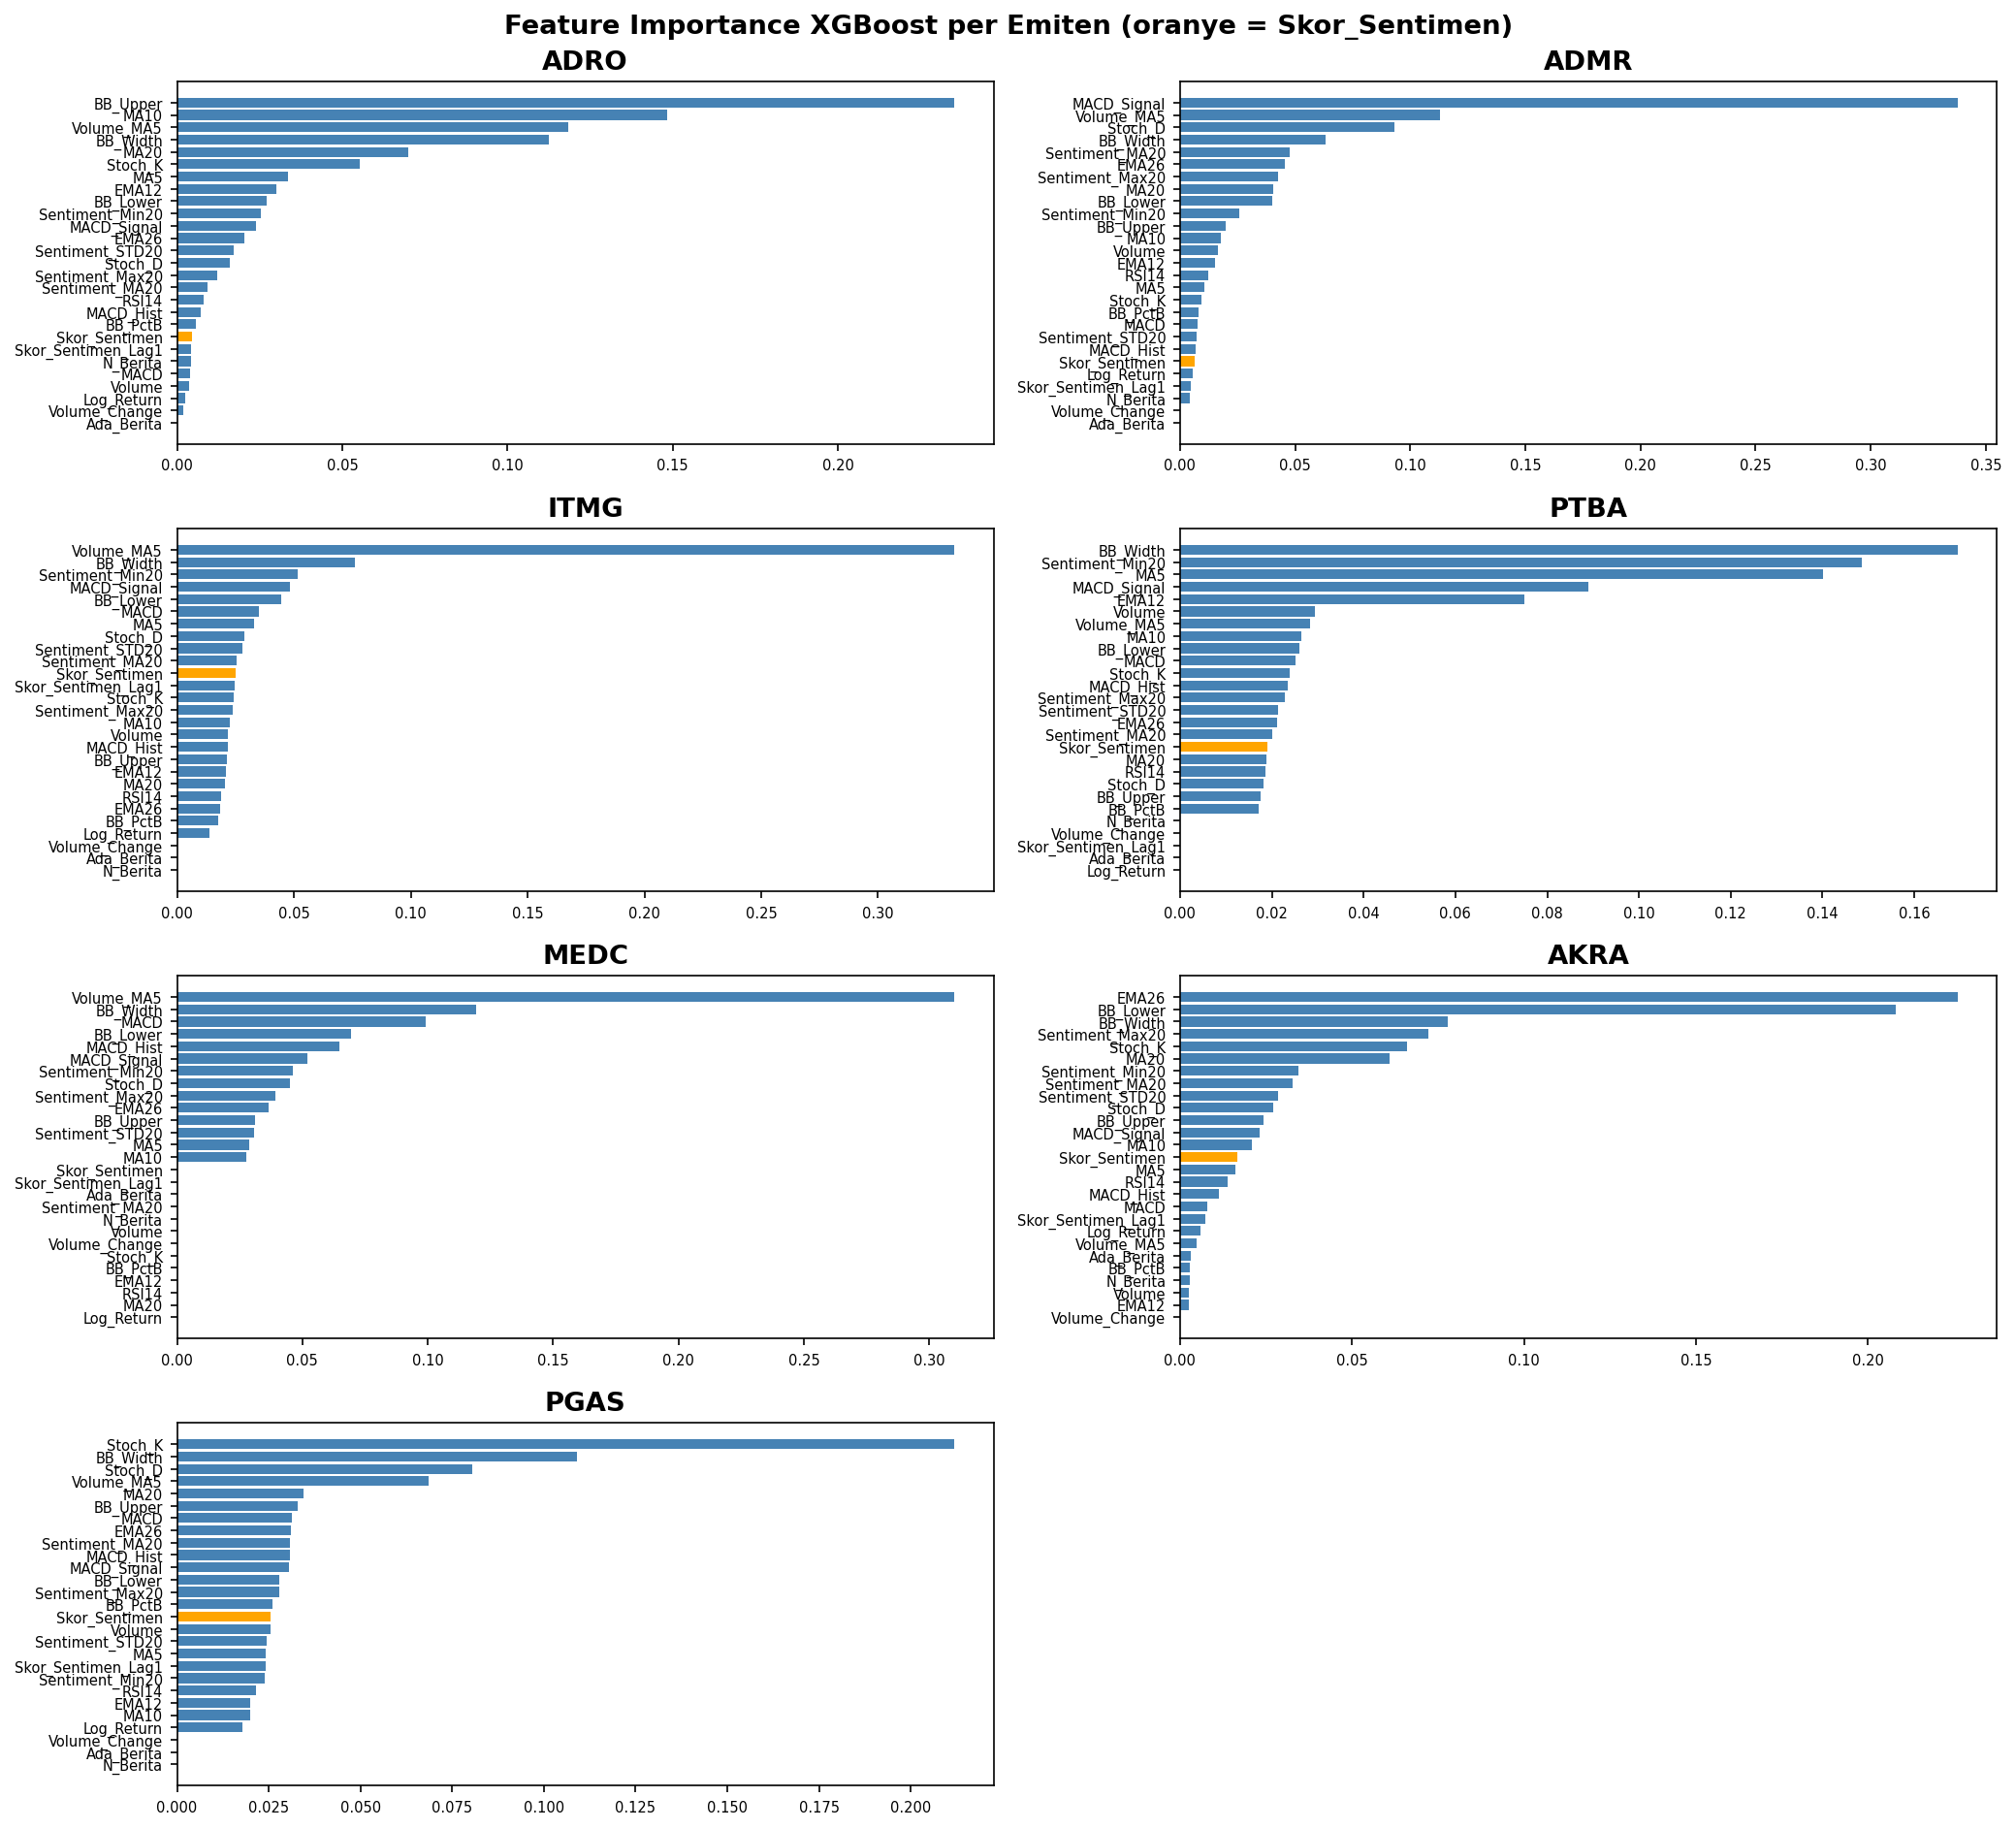

💾 gambar & tabel feature importance tersimpan


In [42]:
print('📊 Feature Importance XGBoost...')
emiten_ok = [e for e in URUTAN_EMITEN if e in dict_hasil_xgb]
ncol = 2; nrow = int(np.ceil(len(emiten_ok)/ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 3.2*nrow)); axes=np.array(axes).ravel()
rows_imp = []
for ax, emiten in zip(axes, emiten_ok):
    model = joblib.load(DIR_MODEL / f'xgboost_{emiten}.pkl')
    kolom_x = dict_kolom_x[emiten]
    imp = pd.Series(model.feature_importances_, index=kolom_x).sort_values()
    warna = ['orange' if f=='Skor_Sentimen' else 'steelblue' for f in imp.index]
    ax.barh(imp.index, imp.values, color=warna)
    ax.set_title(emiten, fontweight='bold'); ax.tick_params(labelsize=7)
    for f,v in imp.items(): rows_imp.append({'Emiten':emiten,'Fitur':f,'Importance':round(float(v),6)})
for ax in axes[len(emiten_ok):]: ax.axis('off')
plt.suptitle('Feature Importance XGBoost per Emiten (oranye = Skor_Sentimen)', fontweight='bold')
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_feature_importance_xgboost.png', dpi=150, bbox_inches='tight')
plt.show()
pd.DataFrame(rows_imp).to_csv(DIR_TABEL / 'tabel_feature_importance_xgboost.csv', encoding='utf-8-sig', index=False)
print('💾 gambar & tabel feature importance tersimpan')

## 📊 CELL 8 — Grafik Aktual vs Prediksi (→ Gambar 4.X)

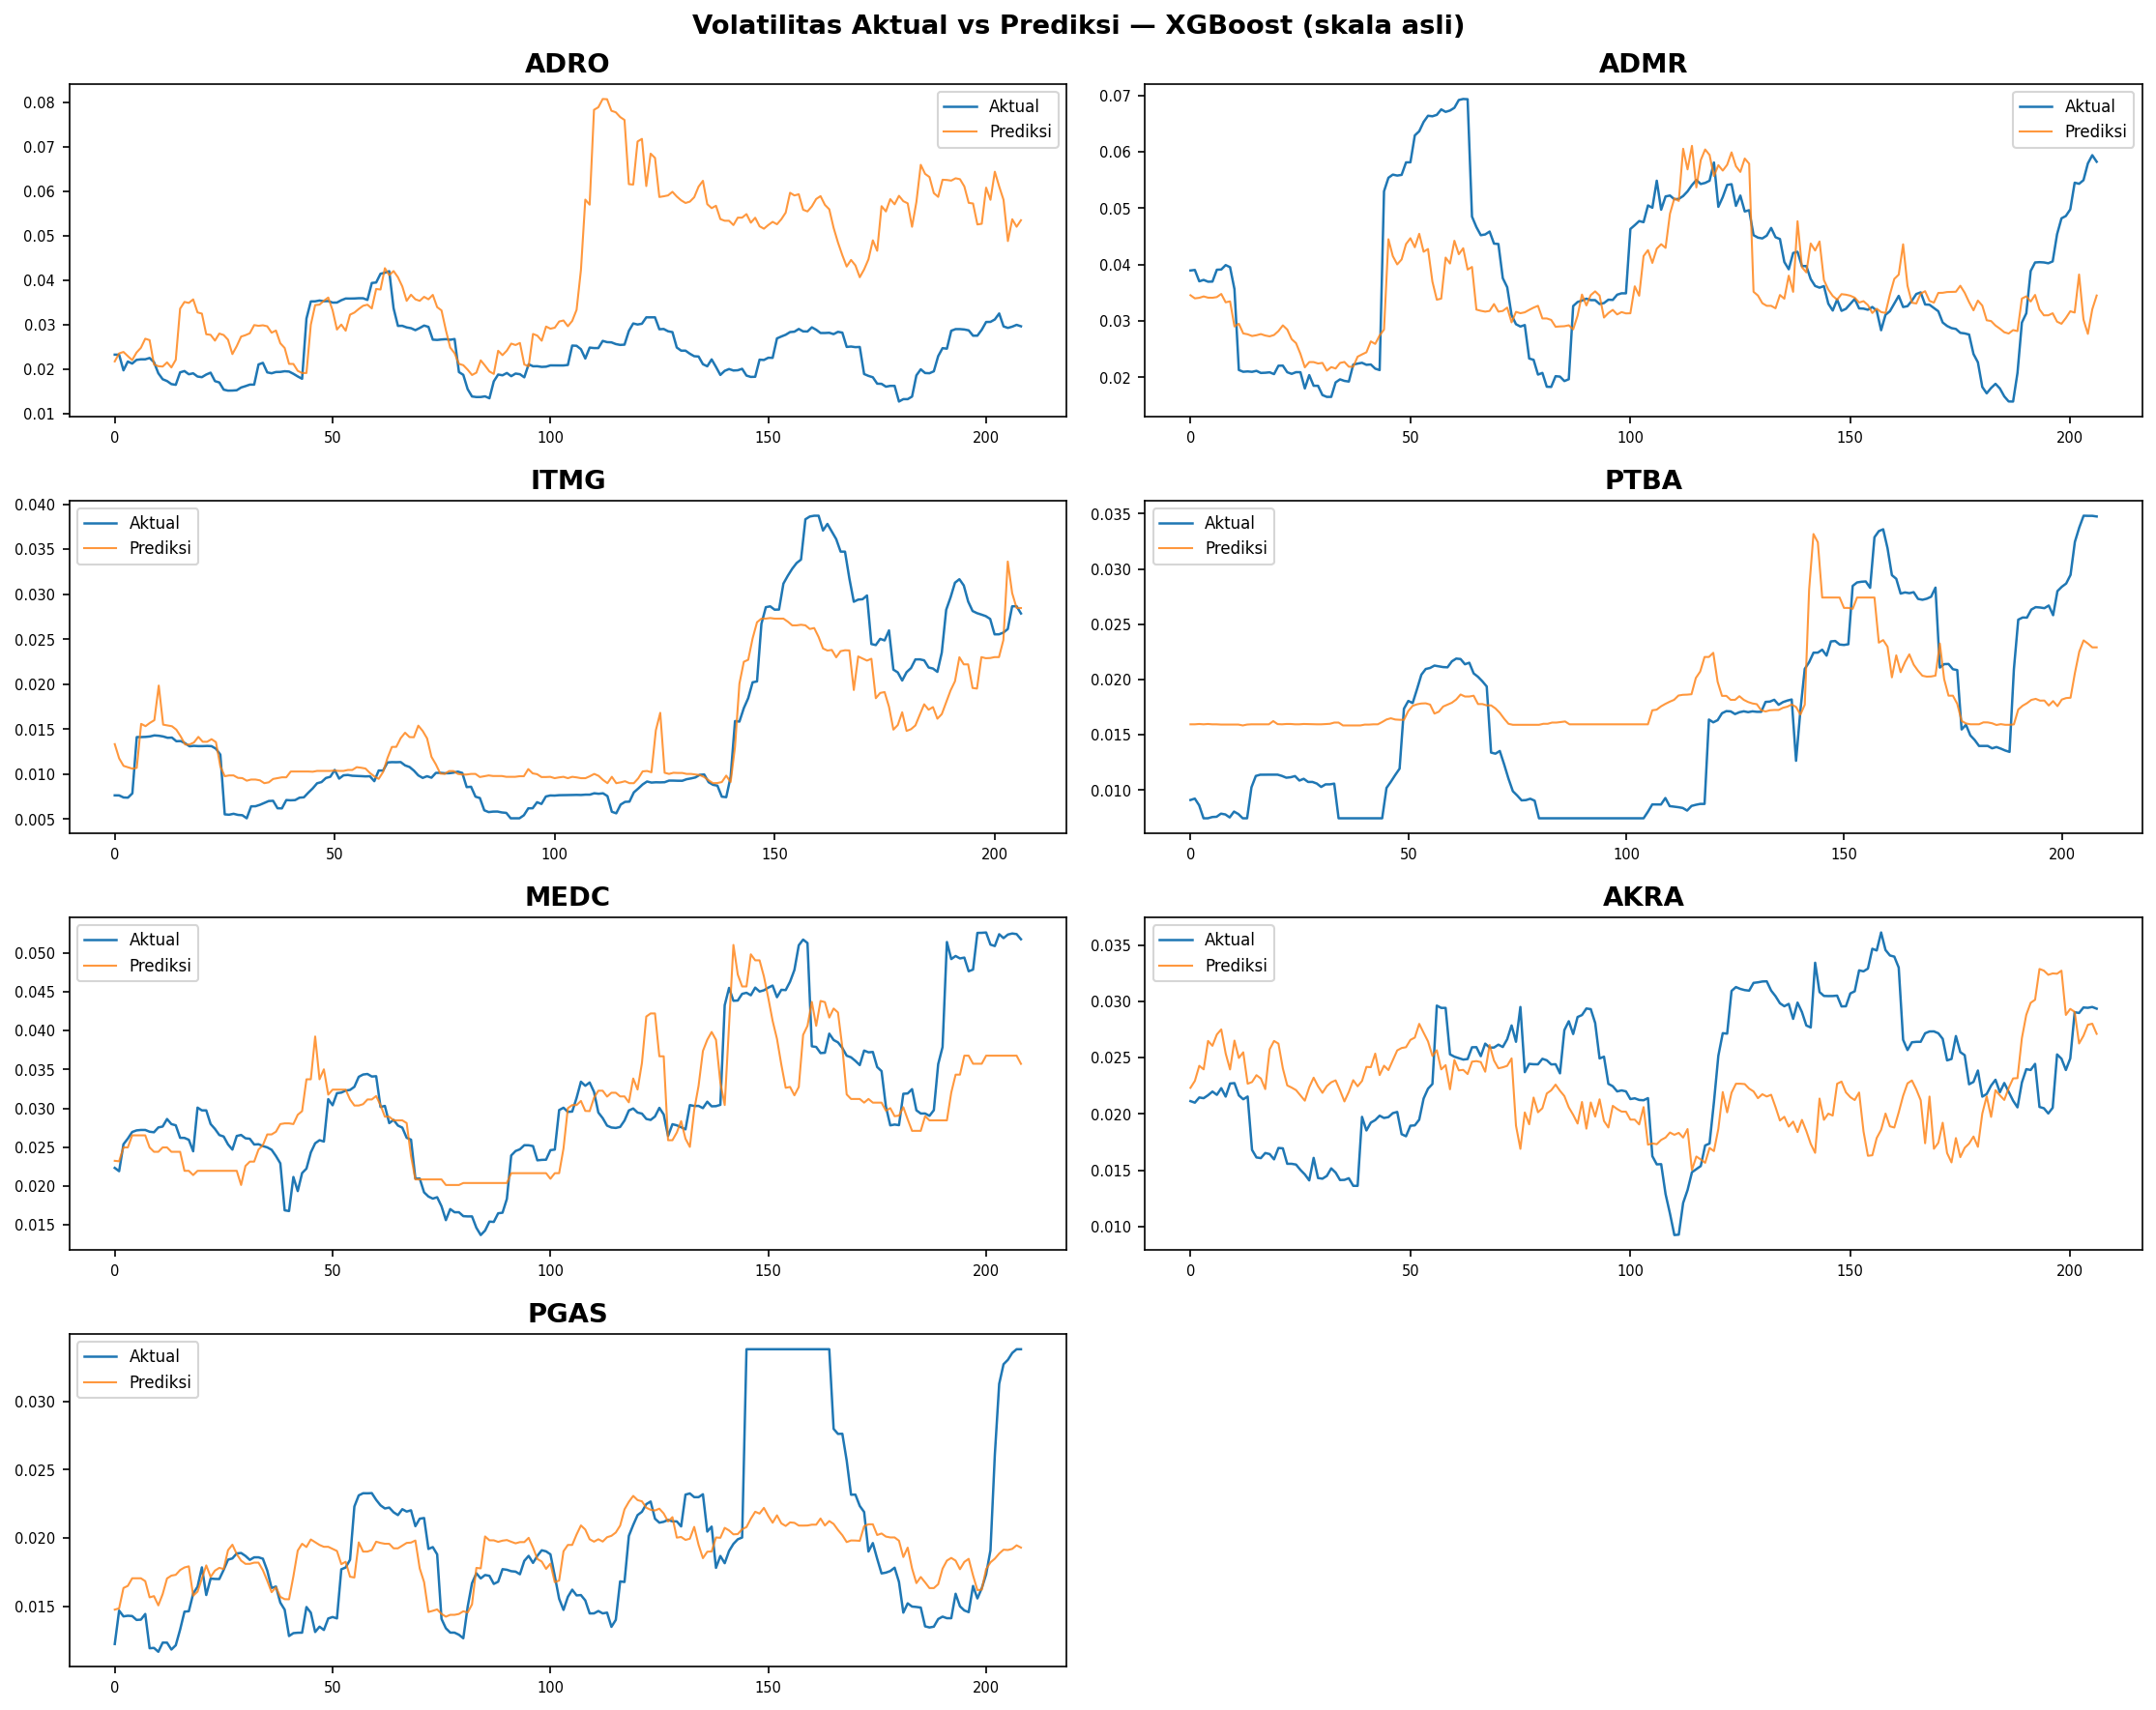

💾 gambar prediksi tersimpan


In [43]:
ncol=2; nrow=int(np.ceil(len(emiten_ok)/ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3*nrow)); axes=np.array(axes).ravel()
for ax, emiten in zip(axes, emiten_ok):
    d = dict_hasil_xgb[emiten]
    ax.plot(d['Y_Aktual'].values, label='Aktual', lw=1.2)
    ax.plot(d['Y_Prediksi'].values, label='Prediksi', lw=1.0, alpha=0.8)
    ax.set_title(emiten, fontweight='bold'); ax.legend(fontsize=8); ax.tick_params(labelsize=7)
for ax in axes[len(emiten_ok):]: ax.axis('off')
plt.suptitle('Volatilitas Aktual vs Prediksi — XGBoost (skala asli)', fontweight='bold')
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_prediksi_xgboost_per_emiten.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 gambar prediksi tersimpan')

## 💾 CELL 9 — Simpan Hasil Prediksi

In [44]:
df_all = pd.concat(dict_hasil_xgb.values(), ignore_index=True)
df_all.to_csv(DIR_TABEL / 'hasil_prediksi_xgboost.csv', encoding='utf-8-sig', index=False)
print('='*70); print('✅ MODEL XGBOOST SELESAI')
print(f'  Hasil prediksi : hasil_prediksi_xgboost.csv ({len(df_all):,} baris)')
print(f'  Model .pkl     : {DIR_MODEL}')
print('  → Lanjut: jalankan MODEL_lstm_FINAL.ipynb lalu EVALUASI_perbandingan.ipynb')
print('='*70)

✅ MODEL XGBOOST SELESAI
  Hasil prediksi : hasil_prediksi_xgboost.csv (1,457 baris)
  Model .pkl     : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\04_model\xgboost
  → Lanjut: jalankan MODEL_lstm_FINAL.ipynb lalu EVALUASI_perbandingan.ipynb


In [47]:
import pandas as pd
import numpy as np

path = r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw\harga_saham_raw.csv'

raw = pd.read_csv(path, parse_dates=['Date'])

d = raw[raw['Kode_Emiten'] == 'ADRO'].sort_values('Date').copy()

d['ret_close'] = np.log(d['Close']).diff()
d['ret_adj']   = np.log(d['Adj Close']).diff()

print(
    d.loc[
        d['ret_close'].abs() > 0.20,
        ['Date', 'Close', 'Adj Close', 'ret_close', 'ret_adj']
    ]
)

           Date   Close    Adj Close  ret_close   ret_adj
1766 2024-11-28  2760.0  2148.349609  -0.284961  0.177195
1767 2024-11-29  2080.0  1619.046021  -0.282863 -0.282863
